# Phase II: Exploratory Analysis and Hypotheses

**Group:** AAH

**NetIDs:** ac3272, asy28, hmr58

This report presents our Phase II exploratory analysis and two planned analyses.

- **Part 1** states the research question, explains how we cleaned the raw data, describes the final dataset, discusses limitations, and presents exploratory data analysis (EDA).
- **Part 2** states two hypotheses and the analyses we plan to run later.

The goal is to show clearly how we go from the raw FDA and CDC files to the final dataset used for analysis.

## 1. Research Question

**Across food-category × pathogen × year rows, to what extent does FDA recall activity track CDC-recorded illness burden?**

In other words, we ask whether rows with more CDC-recorded illnesses also tend to have more FDA recall activity.

Each row in the final dataset represents one **food category, one pathogen, and one year**. For example, `Fruits × Salmonella × 2018` is one row.

We measure:

- **FDA recall activity** as the number of unique FDA recall events in that food-category × pathogen × year row.
- **CDC illness burden** mainly as the total number of recorded illnesses across CDC outbreaks in that row.

An FDA recall and a CDC outbreak are different types of events, so we do not try to match them one-to-one. Instead, we compare them after putting both sources into the same yearly food-category × pathogen format.

### Key Terms

- **Food-category × pathogen × year row:** one food category paired with one pathogen in one year, such as `Fruits × Salmonella × 2018`.
- **FDA recall event:** one recall identified by `RECALLEVENTID`. One recall event can include several product rows.
- **FDA recall activity:** the number of unique FDA recall events in a row.
- **CDC outbreak:** one outbreak recorded in CDC NORS.
- **CDC illness burden:** the amount of illness recorded by CDC for a row; our main measure is total illnesses.
- **Pathogen:** the disease-causing organism involved in a recall or outbreak. We use Salmonella, Listeria, E. coli, and Norovirus.
- **IFSAC category:** CDC's standardized food-category field.
- **Final analysis dataset:** the cleaned and merged dataset used for EDA and later modeling.
- **EDA:** descriptive statistics and plots used to understand the data before the planned statistical tests.
- **Right-skewed:** most values are small, but a few are much larger.
- **`log(1 + x)` transformation:** a transformation that reduces the effect of very large values while keeping zeros.
- **Interaction term:** a regression term used to test whether a relationship differs between groups.
- **Preregistration:** stating a hypothesis and analysis plan before running the final statistical test.

## 2. Data Collection and Cleaning


### 2.1 Data Sources

We use two public datasets.

**FDA food recall data.** The raw FDA file contains product records from the FDA Enforcement Reports API (iRES). Each row is a product record tied to a recall event.

**CDC outbreak data.** The raw CDC NORS file contains recorded outbreaks. Each row is one outbreak record.

The analysis uses these raw input files, relative to the `phase2` notebook:

- `data/fda_food_recalls_raw.csv`
- `data/cdc_nors_raw.csv`

The raw FDA dataset contains **39,833 product records and 12 variables**. The raw CDC NORS dataset contains **66,713 outbreak records and 19 variables**.

The FDA records were collected through the **FDA Enforcement Reports API**. Because the API limits how many records can be returned in one request, the records were downloaded in batches and combined into one raw CSV file. The FDA data-collection code is saved in `fda_recalls.py` in the project repository. The CDC NORS data were downloaded directly as a CSV from the public NORS dataset page.

FDA records recall activity, while CDC NORS records investigated outbreaks. Because these are different events, we do not try to match one FDA recall directly to one CDC outbreak. Instead, we create matching pathogen and food-category variables and aggregate both datasets to the same yearly format.

**Source documentation**

- Project repository: https://github.coecis.cornell.edu/asy28/info2950-final
- FDA iRES API documentation: https://www.accessdata.fda.gov/scripts/ires/apidocs/
- FDA Enforcement Report API definitions: https://www.fda.gov/safety/enforcement-reports/enforcement-report-api-definitions
- CDC NORS dataset page: https://data.cdc.gov/dataset/NORS/5xkq-dg7x
- CDC foodborne outbreak surveillance background: https://www.cdc.gov/nors/about/fdoss.html
- USDA FSIS: https://www.fsis.usda.gov/

### 2.2 Load the Raw Data

We start with the two raw files.

We check their sizes and column names before making any changes.

Import the Python libraries used for cleaning, analysis, and plotting.

In [1]:
# Import the libraries used for data cleaning, analysis, and plotting.

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Load the two raw datasets and check their sizes.

In [2]:
# Load the raw FDA and CDC datasets and print their dimensions.

fda_raw = pd.read_csv("data/fda_food_recalls_raw.csv")
cdc_raw = pd.read_csv("data/cdc_nors_raw.csv", low_memory=False)

print("FDA raw shape:", fda_raw.shape)
print("CDC raw shape:", cdc_raw.shape)

FDA raw shape: (39833, 12)
CDC raw shape: (66713, 19)


Inspect the original column names before cleaning.

In [3]:
# Print the raw column names so we know which fields are available.

print("FDA raw columns:")
print(fda_raw.columns.tolist())

print("\nCDC raw columns:")
print(cdc_raw.columns.tolist())

FDA raw columns:
['PRODUCTID', 'RECALLEVENTID', 'PRODUCTTYPESHORT', 'PHASETXT', 'RECALLINITIATIONDT', 'FIRMLEGALNAM', 'CENTERCLASSIFICATIONTYPETXT', 'ENFORCEMENTREPORTDT', 'PRODUCTDESCRIPTIONTXT', 'PRODUCTSHORTREASONTXT', 'RECALLNUM', 'RID']

CDC raw columns:
['Year', 'Month', 'State', 'Primary Mode', 'Etiology', 'Serotype or Genotype', 'Etiology Status', 'Setting', 'Illnesses', 'Hospitalizations', 'Info On Hospitalizations', 'Deaths', 'Info On Deaths', 'Food Vehicle', 'Food Contaminated Ingredient', 'IFSAC Category', 'Water Exposure', 'Water Type', 'Animal Type']


### 2.2.1 Check for Exact Duplicate Rows

Before cleaning, we check whether either raw file contains rows that are exactly the same across all columns.

The FDA file has a record ID (`RID`), so duplicate records are easy to check. The CDC file does not include a unique outbreak ID. Because of that, two identical CDC rows could be duplicate copies, but they could also be separate outbreaks with the same recorded information.

We report the number of exact matches, but we do not automatically delete identical CDC rows because we cannot prove that they are duplicates.

In the executed raw files, the FDA data contain **0 exact duplicate rows**, while the CDC extract contains **1428 exact matching rows**.

Check both raw datasets for rows that are completely identical across all available columns.

In [4]:
# Count exact duplicate rows in the raw FDA and CDC datasets.

print("FDA exact duplicate rows:", fda_raw.duplicated().sum())
print("CDC exact duplicate rows:", cdc_raw.duplicated().sum())
print("FDA duplicate RID values:", fda_raw["RID"].duplicated().sum())

FDA exact duplicate rows: 0
CDC exact duplicate rows: 1428
FDA duplicate RID values: 0


### 2.3 Clean the FDA Recall Date

The FDA field `RECALLINITIATIONDT` records when each recall started.

We convert it to a date and create `RECALL_YEAR`. We use this year variable to line up FDA and CDC records from the same time period.

In the raw FDA file used here, **2 rows have invalid or implausible recall years**. We treat these dates as missing, so those rows are excluded when we later restrict the FDA data to the shared 2002–2023 period.

Convert the FDA recall-initiation date to a datetime value, flag implausible years as missing, and create the recall-year variable.

In [5]:
# Parse the FDA recall-initiation date, remove clearly invalid historical years, and create a numeric recall year.

fda = fda_raw.copy()

fda["RECALL_DATE"] = pd.to_datetime(
    fda["RECALLINITIATIONDT"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Treat clearly invalid historical years in the raw FDA data as missing.
fda.loc[
    fda["RECALL_DATE"].dt.year < 1900,
    "RECALL_DATE"
] = pd.NaT

fda["RECALL_YEAR"] = fda["RECALL_DATE"].dt.year

print(
    "FDA recall-year range:",
    int(fda["RECALL_YEAR"].min()),
    "-",
    int(fda["RECALL_YEAR"].max())
)

print(
    "Rows with an invalid or unparseable FDA recall date:",
    fda["RECALL_YEAR"].isna().sum()
)


FDA recall-year range: 2001 - 2026
Rows with an invalid or unparseable FDA recall date: 2


### 2.4 Create the FDA Pathogen Variable From Raw Recall Reasons

The raw FDA file does not have a separate pathogen column. It does have `PRODUCTSHORTREASONTXT`, which explains why the product was recalled.

We create a pathogen variable from this text using clear keyword rules for four pathogens that also appear in CDC:

- Salmonella
- Listeria
- E. coli
- Norovirus

Rows that do not mention one of these four pathogens are not used in the final comparative analysis.

All classification rules are shown in the code below.

Create a common FDA pathogen variable directly from the raw recall-reason text.

In [6]:
# Classify FDA recall reasons into the four pathogen groups used in this analysis.

def standardize_fda_pathogen(text):
    text = str(text).lower()

    if "salmonella" in text:
        return "Salmonella"
    elif "listeria" in text or "l. mono" in text or "l monocytogenes" in text:
        return "Listeria"
    elif (
        "escherichia coli" in text
        or "e. coli" in text
        or "e coli" in text
        or "shiga toxin" in text
        or "stec" in text
    ):
        return "E. coli"
    elif "norovirus" in text:
        return "Norovirus"
    else:
        return np.nan

fda["pathogen"] = (
    fda["PRODUCTSHORTREASONTXT"]
    .apply(standardize_fda_pathogen)
)

fda["pathogen"].value_counts(dropna=False)

pathogen
NaN           23476
Listeria       8218
Salmonella     7516
E. coli         584
Norovirus        39
Name: count, dtype: int64

Keep only FDA records involving the four pathogens used in both datasets.

In [7]:
# Keep only FDA rows assigned to one of the four shared pathogen groups.

shared_pathogens = [
    "Salmonella",
    "Listeria",
    "E. coli",
    "Norovirus"
]

fda_pathogen = fda[
    fda["pathogen"].isin(shared_pathogens)
].copy()

print("FDA rows after pathogen filter:", len(fda_pathogen))
fda_pathogen["pathogen"].value_counts()

FDA rows after pathogen filter: 16357


pathogen
Listeria      8218
Salmonella    7516
E. coli        584
Norovirus       39
Name: count, dtype: int64

### 2.5 Restrict CDC to Foodborne Outbreaks and Standardize Pathogens

CDC NORS includes outbreaks spread in different ways. Because our project focuses on food recalls and foodborne outbreaks, we keep only rows where `Primary Mode` is `Food`.

The CDC `Etiology` field can contain detailed pathogen names or subtypes. We convert those names into the same four pathogen labels used in the FDA data.

Inspect the CDC transmission modes before restricting the data to foodborne outbreaks.

In [8]:
# Check how CDC outbreaks are distributed across transmission modes.

cdc_raw["Primary Mode"].value_counts(dropna=False)

Primary Mode
Person-to-person                                     32414
Food                                                 24729
Indeterminate/unknown                                 5677
Water                                                 3106
Animal contact                                         655
Environmental contamination other than food/water      132
Name: count, dtype: int64

Restrict CDC NORS to outbreaks whose primary transmission mode is food.

In [9]:
# Keep only CDC outbreaks where the primary mode of transmission is food.

cdc_food = cdc_raw[
    cdc_raw["Primary Mode"] == "Food"
].copy()

print("CDC foodborne outbreaks:", len(cdc_food))

CDC foodborne outbreaks: 24729


Standardize CDC etiology labels into the same four pathogen groups used for FDA.

In [10]:
# Standardize CDC etiology text into the four shared pathogen categories.

def standardize_cdc_pathogen(text):
    text = str(text).lower()

    if "salmonella" in text:
        return "Salmonella"
    elif "listeria" in text:
        return "Listeria"
    elif (
        "escherichia coli" in text
        or "e. coli" in text
        or "e coli" in text
        or "stec" in text
    ):
        return "E. coli"
    elif "norovirus" in text:
        return "Norovirus"
    else:
        return np.nan

cdc_food["pathogen"] = (
    cdc_food["Etiology"]
    .apply(standardize_cdc_pathogen)
)

cdc_pathogen = cdc_food[
    cdc_food["pathogen"].isin(shared_pathogens)
].copy()

print("CDC outbreaks after pathogen filter:", len(cdc_pathogen))
cdc_pathogen["pathogen"].value_counts()

CDC outbreaks after pathogen filter: 11504


pathogen
Norovirus     7125
Salmonella    3409
E. coli        826
Listeria       144
Name: count, dtype: int64

### 2.6 Clean CDC Food Categories and Match FDA Scope

CDC NORS includes an `IFSAC Category`, which gives a standardized food category.

We remove:

- rows with a missing IFSAC category because there is no food category to match;
- `Multiple` because more than one food category is involved;
- Beef, Chicken, Pork, Turkey, Other Meat, Game, and Other Poultry because these foods are mainly regulated by USDA FSIS rather than the FDA recall source used here.

We keep `Eggs`, but we note in the limitations that egg regulation depends on the type of egg product.

Remove CDC food categories that cannot be compared cleanly with the FDA-focused recall data.

In [11]:
# Remove missing, multiple, and primarily USDA-FSIS food categories from CDC.

fsis_categories = [
    "Beef",
    "Chicken",
    "Pork",
    "Turkey",
    "Other Meat",
    "Game",
    "Other Poultry"
]

cdc_analysis = cdc_pathogen[
    cdc_pathogen["IFSAC Category"].notna()
    & (cdc_pathogen["IFSAC Category"] != "Multiple")
    & (~cdc_pathogen["IFSAC Category"].isin(fsis_categories))
].copy()

cdc_analysis["food_category"] = (
    cdc_analysis["IFSAC Category"]
)

cdc_analysis["food_category"].value_counts()

food_category
Vegetable Row Crops      210
Fruits                   209
Eggs                     179
Dairy                    150
Mollusks                 145
Other                    110
Seeded Vegetables         91
Sprouts                   54
Fish                      39
Root/Underground          34
Grains-beans              30
Nuts-seeds                28
Crustaceans               20
Herbs                     18
Fungi                      8
Oils-sugars                3
Other Aquatic Animals      1
Name: count, dtype: int64

### 2.7 Create Comparable FDA Food Categories From Raw Product Descriptions

The FDA raw file does not contain CDC's IFSAC food category. We create a matching `food_category` from `PRODUCTDESCRIPTIONTXT` using clear keyword rules.

The classifier uses several rules intended to reduce incorrect classifications:

1. it focuses mainly on the product-name part of the description;
2. it uses whole-word matching to reduce accidental matches;
3. it removes products clearly identified as meat or poultry;
4. it checks more specific food categories before broader ones;
5. products that do not match any rule stay unclassified, although some mixed products can still be assigned a category based on the first matching rule.

Create comparable FDA food categories from raw product descriptions using clear keyword rules.

In [12]:
# Classify FDA product descriptions into food categories comparable with CDC IFSAC categories.

def classify_fda_food(text):
    text = str(text).lower()

    title = re.split(
        r"ingredients?:|contains:|ingredient statement|made with|packed by|distributed by",
        text,
        maxsplit=1
    )[0]

    fsis_patterns = [
        r"\bchicken\b", r"\bturkey\b", r"\bpork\b",
        r"\bbeef\b", r"\bham\b", r"\bsausage\b", r"\bjerky\b"
    ]

    if any(re.search(pattern, title) for pattern in fsis_patterns):
        return np.nan

    rules = [
        ("Sprouts", [r"\bsprouts?\b", r"\balfalfa\b"]),
        ("Nuts-seeds", [
            r"\bnuts?\b", r"\bpistachios?\b", r"\bpeanuts?\b",
            r"\bpeanut butter\b", r"\balmonds?\b", r"\bcashews?\b",
            r"\bwalnuts?\b", r"\bpecans?\b", r"\bhazelnuts?\b",
            r"\bmacadamias?\b", r"\bsunflower seeds?\b", r"\bsesame\b"
        ]),
        ("Dairy", [
            r"\bcheese\b", r"\bice cream\b", r"\byogurt\b",
            r"\bmilk\b", r"\bgelato\b"
        ]),
        ("Fish", [
            r"\btuna\b", r"\bsalmon\b", r"\btrout\b",
            r"\bcod\b", r"\btilapia\b"
        ]),
        ("Crustaceans", [
            r"\bshrimp\b", r"\bcrab\b", r"\bkrab\b",
            r"\blobster\b", r"\bcrayfish\b"
        ]),
        ("Mollusks", [
            r"\boysters?\b", r"\bclams?\b",
            r"\bmussels?\b", r"\bscallops?\b"
        ]),
        ("Fruits", [
            r"\bapples?\b", r"\bbananas?\b", r"\bmango(?:es|s)?\b",
            r"\bpineapples?\b", r"\bpeaches?\b", r"\bpears?\b",
            r"\bstrawberries?\b", r"\bblueberries?\b",
            r"\braspberries?\b", r"\bblackberries?\b",
            r"\bcantaloupes?\b", r"\bwatermelons?\b",
            r"\bmelons?\b", r"\bgrapes?\b", r"\boranges?\b",
            r"\bavocados?\b"
        ]),
        ("Seeded Vegetables", [
            r"\btomatoes?\b", r"\bjalapenos?\b", r"\bcucumbers?\b",
            r"\bsquash\b", r"\bzucchini\b", r"\beggplants?\b"
        ]),
        ("Root/Underground", [
            r"\bpotatoes?\b", r"\bcarrots?\b", r"\bbeets?\b",
            r"\bradishes?\b", r"\bsweet potatoes?\b", r"\byams?\b"
        ]),
        ("Vegetable Row Crops", [
            r"\blettuce\b", r"\bspinach\b", r"\bbroccoli\b",
            r"\bcabbage\b", r"\bkale\b", r"\bcauliflower\b",
            r"\bcelery\b"
        ]),
        ("Herbs", [
            r"\bcilantro\b", r"\bparsley\b", r"\bbasil\b"
        ]),
        ("Eggs", [r"\beggs?\b"]),
        ("Grains-beans", [
            r"\brice\b", r"\boats?\b", r"\bwheat\b",
            r"\bbeans?\b", r"\blentils?\b", r"\bbarley\b"
        ])
    ]

    for category, patterns in rules:
        if any(re.search(pattern, title) for pattern in patterns):
            return category

    return np.nan

Apply the FDA food-category classifier and measure how many pathogen-related FDA rows receive a category.

In [13]:
# Apply the food-category classifier and calculate its coverage.

fda_pathogen["food_category"] = (
    fda_pathogen["PRODUCTDESCRIPTIONTXT"]
    .apply(classify_fda_food)
)

classification_rate = (
    fda_pathogen["food_category"].notna().mean() * 100
)

print("FDA food-category counts:")
print(fda_pathogen["food_category"].value_counts(dropna=False))

print(
    "\nPercent of pathogen-related FDA rows classified:",
    round(classification_rate, 2),
    "%"
)

FDA food-category counts:
food_category
NaN                    8287
Nuts-seeds             2911
Dairy                  2002
Fruits                  775
Vegetable Row Crops     459
Fish                    457
Seeded Vegetables       271
Grains-beans            269
Sprouts                 220
Eggs                    196
Crustaceans             178
Root/Underground        160
Herbs                   110
Mollusks                 62
Name: count, dtype: int64

Percent of pathogen-related FDA rows classified: 49.34 %


The classifier assigns a food category to **49.34%** of pathogen-related FDA product rows. The remaining rows are left unclassified. This reduces coverage and limits how often unclear products are forced into a category, but it does not eliminate classification errors.

We inspect a fixed random sample below as a manual check.

Review a fixed random sample of FDA classifications as a manual check.

In [14]:
# Inspect a reproducible sample of FDA product classifications manually.

fda_pathogen[
    ["PRODUCTDESCRIPTIONTXT", "pathogen", "food_category"]
].sample(40, random_state=2)

,PRODUCTDESCRIPTIONTXT,pathogen,food_category
5344,"Reser's Fine Foods, Potato Salad, Formula PO.9...",Listeria,NaN
30179,ZENSHI HANDCRAFTED SUSHI Spicy Grilled Salmon ...,Salmonella,Fish
34353,"NutriSystem Peanut Butter Granola Bar ""Breakfa...",Salmonella,Nuts-seeds
28741,Alfalfa sprouts in 4 ounce clear plastic bags ...,Salmonella,Sprouts
26032,G84827\tSTAGG SILVERADO CHILI SEASONING X1\t45...,Salmonella,NaN
35938,"Fresh Finds, Roasted and Salted Pistachios, Ne...",Salmonella,Nuts-seeds
8430,"Chicken Salad on Wheat, Net Wt. 4.00 oz., UPC ...",Listeria,NaN
29566,"item 8201871\tESL CINNAMON FRIES 60x3OZ, NET W...",Listeria,NaN
6759,Hot Salsa sold under the following sizes and b...,Listeria,NaN
37754,ILLES SEASONINGS & FLAVORS AU JUS SEASONING 63...,Salmonella,NaN


The sample includes both clear matches and some imperfect classifications. For example, **“Broccoli Crunch Kit, Alaska Carrot brand”** is classified as `Nuts-seeds`, even though the product name points more clearly to a vegetable product. This check shows that the keyword classifier is a practical matching rule rather than an exact labeling system, which is why classification error is included in the limitations section.

### 2.8 Restrict FDA and CDC to the Same Time Period

The two datasets cover different year ranges. To make the totals comparable, we use the overlapping year range covered by both sources.

The shared period is **2002–2023**.

Find the years covered by both FDA and CDC so the two sources use the same observation period.

In [15]:
# Find the overlapping FDA-CDC year range.

common_start = max(
    fda_pathogen["RECALL_YEAR"].min(),
    cdc_analysis["Year"].min()
)

common_end = min(
    fda_pathogen["RECALL_YEAR"].max(),
    cdc_analysis["Year"].max()
)

print("FDA year range:",
      int(fda_pathogen["RECALL_YEAR"].min()),
      "-",
      int(fda_pathogen["RECALL_YEAR"].max()))

print("CDC year range:",
      int(cdc_analysis["Year"].min()),
      "-",
      int(cdc_analysis["Year"].max()))

print("Shared analysis period:",
      int(common_start),
      "-",
      int(common_end))

FDA year range: 2002 - 2026
CDC year range: 1998 - 2023
Shared analysis period: 2002 - 2023


Restrict both datasets to the shared years and keep FDA rows with usable food categories.

In [16]:
# Restrict FDA and CDC to the shared time period and usable FDA food categories.

fda_common = fda_pathogen[
    (fda_pathogen["RECALL_YEAR"] >= common_start)
    & (fda_pathogen["RECALL_YEAR"] <= common_end)
    & (fda_pathogen["food_category"].notna())
].copy()

cdc_common = cdc_analysis[
    (cdc_analysis["Year"] >= common_start)
    & (cdc_analysis["Year"] <= common_end)
].copy()

print("FDA usable rows in shared period:", len(fda_common))
print("CDC usable outbreaks in shared period:", len(cdc_common))

FDA usable rows in shared period: 7453
CDC usable outbreaks in shared period: 1106


### 2.9 Convert CDC Burden Variables to Numeric

Some CDC count fields are read as text because they contain missing values or mixed data types.

We convert illnesses, hospitalizations, deaths, and hospitalization-information fields to numeric values before aggregation. Values that cannot be converted become missing (`NaN`).

Convert CDC burden variables to numeric values before aggregation.

In [17]:
# Convert CDC illness, hospitalization, death, and coverage fields to numeric values.

numeric_cols = [
    "Illnesses",
    "Hospitalizations",
    "Deaths",
    "Info On Hospitalizations"
]

for col in numeric_cols:
    cdc_common[col] = pd.to_numeric(
        cdc_common[col],
        errors="coerce"
    )

cdc_common[numeric_cols].dtypes

Illnesses                   float64
Hospitalizations            float64
Deaths                      float64
Info On Hospitalizations    float64
dtype: object

### 2.10 Aggregate FDA Recall Activity

One FDA recall event can appear in several product rows. Counting product rows would count the same recall more than once.

We therefore count **unique `RECALLEVENTID` values** for each year, food category, and pathogen.

After this step, each FDA summary row represents one food-category × pathogen × year row, and `fda_recall_events` is the number of distinct recall events in that row.

Aggregate FDA recall activity by **year, food category, and pathogen** so that each FDA summary row matches the annual unit used in the analysis.

In [18]:
# Count unique FDA recall events for each year, food category, and pathogen.

fda_agg = (
    fda_common
    .groupby(["RECALL_YEAR", "food_category", "pathogen"])
    .agg(
        fda_recall_events=("RECALLEVENTID", "nunique")
    )
    .reset_index()
    .rename(columns={"RECALL_YEAR": "year"})
)

fda_agg["year"] = fda_agg["year"].astype(int)

fda_agg.sort_values(
    "fda_recall_events",
    ascending=False
).head(10)

,year,food_category,pathogen,fda_recall_events
75,2009,Nuts-seeds,Salmonella,460
64,2009,Dairy,Salmonella,52
153,2012,Nuts-seeds,Salmonella,50
11,2004,Nuts-seeds,Salmonella,50
246,2016,Nuts-seeds,Listeria,43
219,2015,Nuts-seeds,Salmonella,36
98,2010,Nuts-seeds,Salmonella,31
260,2017,Dairy,Listeria,27
394,2022,Nuts-seeds,Salmonella,27
185,2014,Dairy,Listeria,26


### 2.11 Aggregate CDC Illness Burden

We aggregate CDC outbreaks to the same food-category × pathogen × year format.

For each row we calculate:

- `cdc_outbreaks`: number of recorded outbreaks
- `total_illnesses`: total recorded illnesses
- `total_hospitalizations`: total recorded hospitalizations
- `total_deaths`: total recorded deaths
- `hospitalization_info`: sum of the CDC `Info On Hospitalizations` field

Our main CDC burden measure is **total illnesses**.

If all outbreak records in a group are missing a given burden field, the aggregated value for that field remains missing instead of being changed to 0.

Aggregate CDC outbreak counts and health-burden measures by **year, food category, and pathogen** so that CDC uses the same annual unit as FDA.

In [19]:
# Aggregate CDC outbreaks and health-burden measures by year, food category, and pathogen.

cdc_agg = (
    cdc_common
    .groupby(["Year", "food_category", "pathogen"])
    .agg(
        cdc_outbreaks=("pathogen", "size"),
        total_illnesses=("Illnesses", lambda x: x.sum(min_count=1)),
        total_hospitalizations=("Hospitalizations", lambda x: x.sum(min_count=1)),
        total_deaths=("Deaths", lambda x: x.sum(min_count=1)),
        hospitalization_info=("Info On Hospitalizations", lambda x: x.sum(min_count=1))
    )
    .reset_index()
    .rename(columns={"Year": "year"})
)

cdc_agg.head()

,year,food_category,pathogen,cdc_outbreaks,total_illnesses,total_hospitalizations,total_deaths,hospitalization_info
0,2002,Dairy,Norovirus,1,25.0,0.0,0.0,23.0
1,2002,Dairy,Salmonella,3,230.0,12.0,0.0,167.0
2,2002,Eggs,Norovirus,1,29.0,0.0,0.0,29.0
3,2002,Eggs,Salmonella,7,392.0,55.0,0.0,355.0
4,2002,Fish,Norovirus,1,22.0,0.0,0.0,16.0


### 2.12 Merge FDA and CDC and Create the Final Dataset

The FDA and CDC summaries use the same three matching variables:

- `year`
- `food_category`
- `pathogen`

We remove the CDC categories Other, Fungi, Oils-sugars, and Other Aquatic Animals because the FDA classifier does not create directly matching categories for them.

Next, we keep every food-category × pathogen pair that appears at least once in **either** dataset during 2002–2023. Using the union of both sources keeps important cases where one source records activity and the other does not.

For each pair, we create one row for every year from 2002 through 2023.

If CDC has no recorded outbreak for a pair in a given year, its outbreak and burden counts are set to 0. If FDA has no recorded recall event, its recall-event count is set to 0. If CDC has an outbreak but an illness, hospitalization, death, or hospitalization-information value is missing, that value stays missing.

This produces the final yearly panel used for EDA and later modeling.

The executed workflow retains **51 food-category × pathogen pairs**. Across 22 years, this produces **1122 final annual observations**.

Create the complete **food-category × pathogen × year panel** from all comparable pairs observed in either source, merge the annual FDA and CDC summaries, and use 0 when a source has no recorded event for that year.

In [20]:
# Build a complete annual panel for food-category × pathogen pairs observed in either source.

# Remove CDC categories that do not have directly comparable FDA classifier categories.
unmatched_cdc_categories = [
    "Other",
    "Fungi",
    "Oils-sugars",
    "Other Aquatic Animals"
]

cdc_agg = cdc_agg[
    ~cdc_agg["food_category"].isin(unmatched_cdc_categories)
].copy()

# Identify every food-category × pathogen pair observed in at least one source.
fda_pairs = set(
    map(tuple, fda_agg[["food_category", "pathogen"]].drop_duplicates().to_numpy())
)
cdc_pairs = set(
    map(tuple, cdc_agg[["food_category", "pathogen"]].drop_duplicates().to_numpy())
)

analysis_pairs = sorted(fda_pairs | cdc_pairs)

print("Food-category × pathogen pairs in final panel:", len(analysis_pairs))

# Create one row for every retained pair in every year from 2002 through 2023.
panel_rows = [
    {
        "year": year,
        "food_category": food_category,
        "pathogen": pathogen
    }
    for food_category, pathogen in analysis_pairs
    for year in range(int(common_start), int(common_end) + 1)
]

analysis_df = pd.DataFrame(panel_rows)

# Merge annual CDC burden and FDA recall activity onto the complete panel.
analysis_df = analysis_df.merge(
    cdc_agg,
    on=["year", "food_category", "pathogen"],
    how="left"
)

analysis_df = analysis_df.merge(
    fda_agg,
    on=["year", "food_category", "pathogen"],
    how="left"
)

# Track rows where CDC recorded no outbreak at all for that year/pair.
no_cdc_outbreak = analysis_df["cdc_outbreaks"].isna()

# If CDC recorded no outbreak, the annual CDC event and burden counts are 0.
analysis_df.loc[
    no_cdc_outbreak,
    [
        "cdc_outbreaks",
        "total_illnesses",
        "total_hospitalizations",
        "total_deaths",
        "hospitalization_info"
    ]
] = 0

# If FDA recorded no recall event, the annual FDA recall count is 0.
analysis_df["fda_recall_events"] = (
    analysis_df["fda_recall_events"]
    .fillna(0)
    .astype(int)
)

analysis_df["cdc_outbreaks"] = (
    analysis_df["cdc_outbreaks"]
    .fillna(0)
    .astype(int)
)


analysis_df = analysis_df.sort_values(
    ["year", "food_category", "pathogen"]
).reset_index(drop=True)

print("Final analysis rows:", len(analysis_df))
print("Years:", analysis_df["year"].min(), "-", analysis_df["year"].max())
analysis_df.head(10)

Food-category × pathogen pairs in final panel: 51
Final analysis rows: 1122
Years: 2002 - 2023


,year,food_category,pathogen,cdc_outbreaks,total_illnesses,total_hospitalizations,total_deaths,hospitalization_info,fda_recall_events
0,2002,Crustaceans,E. coli,0,0.0,0.0,0.0,0.0,0
1,2002,Crustaceans,Listeria,0,0.0,0.0,0.0,0.0,0
2,2002,Crustaceans,Norovirus,0,0.0,0.0,0.0,0.0,0
3,2002,Crustaceans,Salmonella,0,0.0,0.0,0.0,0.0,0
4,2002,Dairy,E. coli,0,0.0,0.0,0.0,0.0,0
5,2002,Dairy,Listeria,0,0.0,0.0,0.0,0.0,3
6,2002,Dairy,Norovirus,1,25.0,0.0,0.0,23.0,0
7,2002,Dairy,Salmonella,3,230.0,12.0,0.0,167.0,0
8,2002,Eggs,E. coli,0,0.0,0.0,0.0,0.0,0
9,2002,Eggs,Listeria,0,0.0,0.0,0.0,0.0,0


### 2.13 Save the Cleaned and Final Files

The cleaning process creates these files:

- `fda_food_recalls_phase2_clean.csv`
- `cdc_nors_clean.csv`
- `food_pathogen_analysis.csv`

The cleaned CDC file includes categories later removed in Section 2.12 because they do not have directly matching FDA classifier categories.

The full data flow is:

**raw FDA + raw CDC → cleaning → yearly aggregation → full food-category × pathogen × year panel → final dataset**

Save the cleaned intermediate files and final analysis dataset.

In [21]:
# Save the cleaned FDA and CDC files and the final merged analysis dataset.

fda_common.to_csv(
    "data/fda_food_recalls_phase2_clean.csv",
    index=False
)

cdc_common.to_csv(
    "data/cdc_nors_clean.csv",
    index=False
)

analysis_df.to_csv(
    "data/food_pathogen_analysis.csv",
    index=False
)

print("Saved final analysis rows:", len(analysis_df))

Saved final analysis rows: 1122


## 3. Data Description


### 3.1 What Does Each Row Represent?

- In the raw FDA data, one row is one FDA product record tied to a recall.
- In the raw CDC data, one row is one outbreak record.
- In the final dataset, one row is one **food-category × pathogen × year** row.

For example, `Fruits × Salmonella × 2018` is one row.

The final dataset is not one row per person, product, recall, or outbreak. Instead, each row combines FDA and CDC information for one food category, one pathogen, and one year.

### 3.2 What Are the Final Attributes?

The final dataset contains:

- `year`: calendar year
- `food_category`: common food category used to align the FDA and CDC data
- `pathogen`: Salmonella, Listeria, E. coli, or Norovirus
- `cdc_outbreaks`: number of CDC outbreaks in that row
- `total_illnesses`: total recorded illnesses
- `total_hospitalizations`: total recorded hospitalizations
- `total_deaths`: total recorded deaths
- `hospitalization_info`: sum of the CDC `Info On Hospitalizations` field
- `fda_recall_events`: number of unique FDA recall events

The first three variables identify the row. The remaining variables summarize CDC burden and FDA recall activity for that row.

### 3.3 Why Were These Datasets Created?

We created the final analysis dataset to compare FDA recall activity with CDC-recorded illness burden using a common food-category × pathogen × year unit.

The **U.S. Food and Drug Administration (FDA)** publishes the Enforcement Reports data to document FDA recall activity. These are administrative records, so they do not measure every food-safety problem.

The **Centers for Disease Control and Prevention (CDC)** publishes NORS data to record investigated disease outbreaks. NORS includes fields such as pathogen, implicated food, illnesses, hospitalizations, deaths, and setting.

We follow each agency's public documentation for the dataset and field definitions. Because the two datasets were created for different purposes, we should not expect their patterns to match exactly.

### 3.4 How Was the Final Dataset Created?

Using Python and pandas, we:

1. loaded the raw FDA and CDC files;
2. parsed the raw FDA recall date, treated implausible years as missing, and created recall year;
3. created FDA pathogen directly from the raw recall-reason text;
4. restricted CDC to foodborne outbreaks;
5. standardized CDC etiology into the same four pathogens;
6. removed CDC food categories that were missing, ambiguous, mainly outside FDA jurisdiction, or did not have a directly matching FDA classifier category;
7. created FDA food categories from raw product-description text;
8. restricted both sources to 2002–2023;
9. converted CDC burden fields to numeric values;
10. counted unique FDA recall events by year, food category, and pathogen;
11. aggregated CDC burden by the same year, food category, and pathogen unit;
12. kept all comparable food-category × pathogen pairs observed in either source;
13. created a complete 2002–2023 annual panel for those pairs;
14. merged the FDA and CDC annual summaries onto that panel;
15. recorded 0 when a source had no event for a pair-year while keeping missing CDC illness, hospitalization, death, and hospitalization-information values when an outbreak occurred but the field was not reported;
16. saved intermediate and final files.

### 3.5 What Affects What Gets Recorded?

FDA recall activity depends on factors such as testing, company reporting, FDA monitoring, product distribution, and which agency regulates the food.

CDC NORS includes outbreaks that were detected, investigated, and reported. It does not capture every case of foodborne illness.

Because of these differences, neither dataset gives a complete count of all food-safety problems.

### 3.6 Were People Involved in the Data Collection?

We did not directly survey or contact anyone.

CDC NORS contains aggregate outbreak information about people who became ill, were hospitalized, or died. We do not try to identify anyone.

The FDA data focus on firms, products, and recalls rather than individual consumers.

The available datasets do not say whether affected individuals knew that information about their illnesses could later appear in aggregate surveillance data.

### 3.7 Where Can the Raw Data Be Found?

The project repository is:

https://github.coecis.cornell.edu/asy28/info2950-final

From the repository root, the raw files used by this notebook are located at:

- `phase2/data/fda_food_recalls_raw.csv` — https://github.coecis.cornell.edu/asy28/info2950-final/blob/main/phase2/data/fda_food_recalls_raw.csv
- `phase2/data/cdc_nors_raw.csv` — https://github.coecis.cornell.edu/asy28/info2950-final/blob/main/phase2/data/cdc_nors_raw.csv

The public-source documentation is linked in Section 2.1.

## 4. Data Limitations

**FDA recalls and CDC outbreaks measure different things.**

An FDA recall is a recall action involving a product. A CDC outbreak is a recorded public-health event involving illness. One recall does not necessarily match one outbreak, and one outbreak does not necessarily lead to a recall.

**FDA pathogen labels are created from text.**

The raw FDA file does not have a pathogen column, so we identify pathogens from the recall-reason text using clear keyword rules. Some descriptions may use wording that our rules do not recognize, which can cause missed or incorrect classifications.

**FDA food categories are created from product descriptions.**

The FDA file does not include CDC IFSAC food categories, so we assign categories using keyword rules based on product descriptions. Products that cannot be clearly classified are left unclassified and excluded from category-level comparisons, which may cause FDA recall activity to be understated for some categories. Some mixed products may also be placed in the wrong category because the classifier uses the first matching rule, as shown in the manual check in Section 2.7.

**One FDA recall event can contribute to more than one food category.**

A recall event can contain several product records, and different products from the same recall can be assigned to different food categories. We count each recall event only once within a food-category × pathogen × year row, but totals summed across food categories are not necessarily globally unique recall events.

**CDC NORS does not capture every foodborne illness.**

An outbreak must be detected, investigated, and reported to appear in NORS. A value of 0 means no outbreak was recorded in NORS for that row; it does not prove that no outbreak occurred.

**Some CDC burden values are missing.**

When an outbreak is recorded but the corresponding count is missing, we keep that value as missing instead of changing it to 0. Rows with a missing illness total cannot be used in models where illness burden is the predictor.

**Identical CDC rows are difficult to interpret.**

The CDC file contains rows that are identical across all available columns, but it does not include a unique outbreak ID. We cannot tell whether every identical row is a duplicate copy or a separate outbreak with the same recorded information. We keep these rows instead of deleting possibly valid outbreaks.

**FDA and USDA regulate different foods.**

We remove meat and poultry categories that are mainly regulated by USDA FSIS. Egg regulation depends on the type of egg product, so results involving eggs should be interpreted with extra caution.

**The same food-category × pathogen pair appears in many years.**

Rows from the same pair may be more similar to each other than to unrelated rows. The categorical controls in our planned models may reduce some of these differences, but they may not fully account for this repeated structure.

**The data are based on observed records, so the results do not show causation.**

A relationship between illness burden and recall activity does not show that one causes the other.

**Recall counts are not a direct food-safety score.**

A high recall count can reflect more testing, wider product distribution, better detection, or more active monitoring. A low recall count does not necessarily mean a food category is safer.

**Misreading the results could affect consumers and industries.**

Treating recall counts as a ranking of food safety could unfairly change how people view certain foods, producers, or industries. We use the results only to compare patterns in the FDA and CDC data, not to label foods as safe or unsafe.

## 5. Exploratory Data Analysis

EDA uses summary statistics and plots to understand the data before the planned statistical tests.

Our EDA focuses on:

1. the typical size and spread of the main variables;
2. the relationship between CDC illness burden and FDA recall activity;
3. differences across pathogens and food categories;
4. changes across years.

The planned regression models are not run in this Phase II notebook.

### 5.1 Summary Statistics

Summarize the main numeric variables in the final analysis dataset.

In [22]:
# Compute descriptive statistics for the main CDC burden and FDA recall variables.

analysis_df[
    [
        "cdc_outbreaks",
        "total_illnesses",
        "total_hospitalizations",
        "total_deaths",
        "fda_recall_events"
    ]
].describe()

,cdc_outbreaks,total_illnesses,total_hospitalizations,total_deaths,fda_recall_events
count,1122.000000,1121.000000,1110.000000,1106.000000,1122.000000
mean,0.897504,27.777877,5.141441,0.147378,2.255793
std,1.785363,83.548402,22.210177,1.202177,14.468878
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,16.000000,1.000000,0.000000,2.000000
max,20.000000,1048.000000,308.000000,33.000000,460.000000


The summary statistics show a lot of variation across food-category × pathogen × year rows. Many annual observations have no recorded CDC outbreak or FDA recall event, so the medians of several count variables are 0. At the same time, a small number of observations have much larger illness and recall counts. This combination of many zeros and a long right tail motivates showing both the original scale and a `log(1 + x)` scale in the scatterplots below.

### 5.2 FDA Recall Activity vs. CDC-Recorded Illnesses

Each point represents one food-category × pathogen × year row.

Plot FDA recall activity against CDC-recorded illnesses on the original scale.

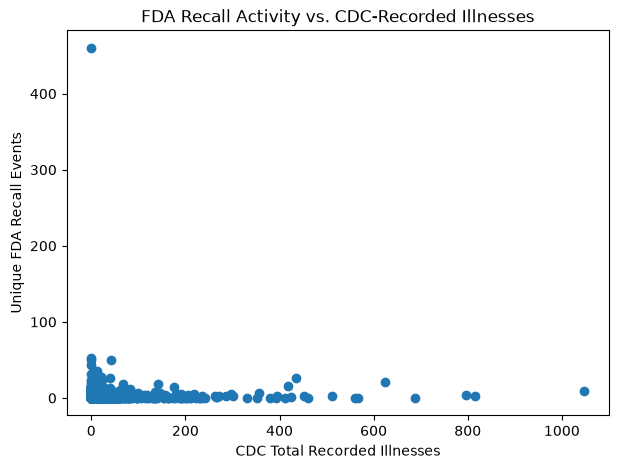

In [23]:
# Plot FDA recall events against CDC total illnesses on the original scale.

plt.figure(figsize=(7, 5))
plt.scatter(
    analysis_df["total_illnesses"],
    analysis_df["fda_recall_events"]
)
plt.xlabel("CDC Total Recorded Illnesses")
plt.ylabel("Unique FDA Recall Events")
plt.title("FDA Recall Activity vs. CDC-Recorded Illnesses")
plt.show()

A small number of large observations dominate the raw-scale plot. The log-scale version below compresses large values while retaining zero values.

Plot the same relationship on a `log(1 + x)` scale to reduce the visual influence of very large values.

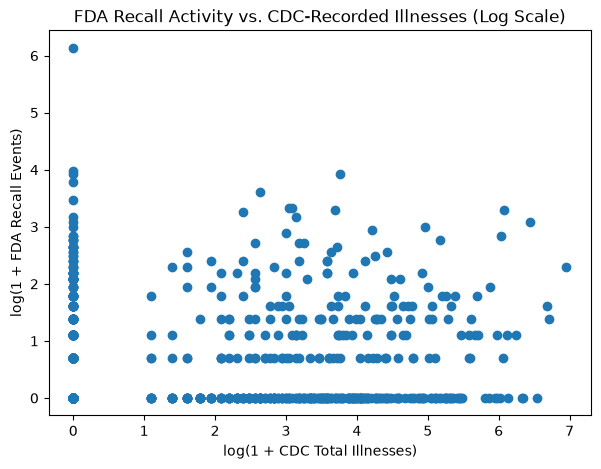

In [24]:
# Plot illness burden and recall activity on a log(1 + x) scale.

plt.figure(figsize=(7, 5))
plt.scatter(
    np.log1p(analysis_df["total_illnesses"]),
    np.log1p(analysis_df["fda_recall_events"])
)
plt.xlabel("log(1 + CDC Total Illnesses)")
plt.ylabel("log(1 + FDA Recall Events)")
plt.title("FDA Recall Activity vs. CDC-Recorded Illnesses (Log Scale)")
plt.show()

The log-scale plot does not show a strong or consistent relationship between CDC-recorded illness burden and FDA recall activity. We treat this as descriptive EDA and do not fit the planned regression here.

### 5.3 Differences Across Pathogens

Summarize the annual panel by pathogen to compare total CDC burden and FDA recall activity across the four pathogen groups.

In [25]:
# Summarize the annual panel by pathogen.

pathogen_summary = (
    analysis_df
    .groupby("pathogen")
    .agg(
        observations=("year", "size"),
        total_cdc_outbreaks=("cdc_outbreaks", "sum"),
        total_illnesses=("total_illnesses", "sum"),
        total_fda_recall_events=("fda_recall_events", "sum")
    )
    .sort_values("total_illnesses", ascending=False)
)

pathogen_summary

,observations,total_cdc_outbreaks,total_illnesses,total_fda_recall_events
pathogen,,,,
Salmonella,286,442,18651.0,1400
Norovirus,264,356,8110.0,18
E. coli,286,158,3754.0,87
Listeria,286,51,624.0,1026


Show the log-scale illness-recall relationship separately by pathogen.

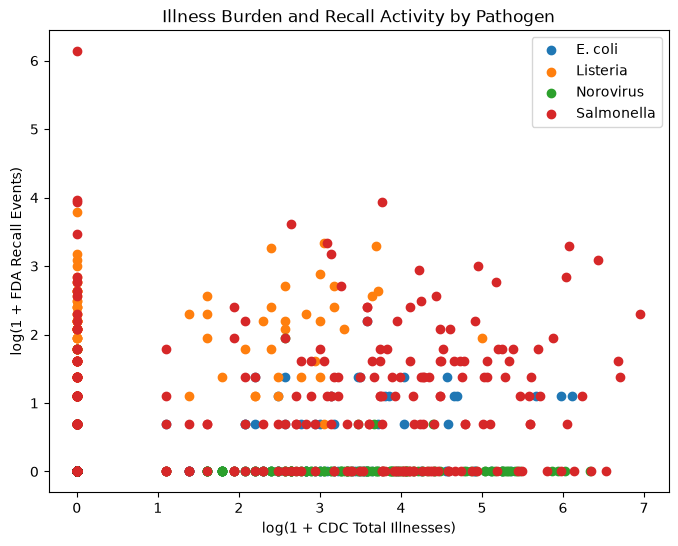

In [26]:
# Plot the log-scale relationship and label points by pathogen.

plt.figure(figsize=(8, 6))

for pathogen, group in analysis_df.groupby("pathogen"):
    plt.scatter(
        np.log1p(group["total_illnesses"]),
        np.log1p(group["fda_recall_events"]),
        label=pathogen
    )

plt.xlabel("log(1 + CDC Total Illnesses)")
plt.ylabel("log(1 + FDA Recall Events)")
plt.title("Illness Burden and Recall Activity by Pathogen")
plt.legend()
plt.show()

The summaries show substantial differences in illness burden and recall activity across pathogens. We therefore include pathogen as a categorical control in the planned regression models.

### 5.4 Differences Across Food Categories

Summarize the annual panel by food category to compare total CDC burden and FDA recall activity across categories.

In [27]:
# Summarize the annual panel by food category.

food_summary = (
    analysis_df
    .groupby("food_category")
    .agg(
        observations=("year", "size"),
        total_cdc_outbreaks=("cdc_outbreaks", "sum"),
        total_illnesses=("total_illnesses", "sum"),
        total_fda_recall_events=("fda_recall_events", "sum")
    )
    .sort_values("total_illnesses", ascending=False)
)

food_summary

,observations,total_cdc_outbreaks,total_illnesses,total_fda_recall_events
food_category,,,,
Fruits,88,168,6891.0,276
Vegetable Row Crops,88,186,5360.0,179
Seeded Vegetables,88,86,5259.0,112
Eggs,88,116,2372.0,78
Nuts-seeds,88,27,2095.0,889
Dairy,88,133,2086.0,390
Mollusks,88,126,1957.0,29
Fish,88,32,1478.0,159
Sprouts,66,43,1298.0,91


Compare total CDC-recorded illnesses across food categories.

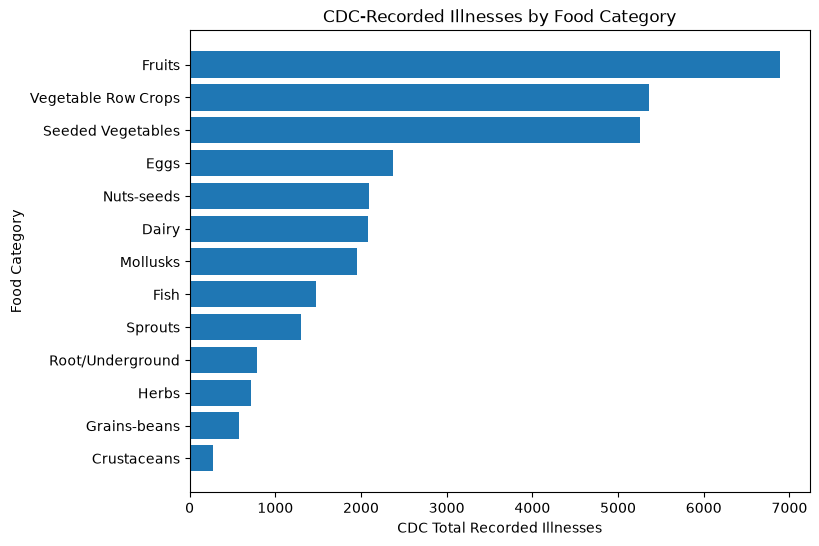

In [28]:
# Plot total CDC-recorded illnesses for each food category.

food_plot = food_summary.sort_values(
    "total_illnesses",
    ascending=True
)

plt.figure(figsize=(8, 6))
plt.barh(
    food_plot.index,
    food_plot["total_illnesses"]
)
plt.xlabel("CDC Total Recorded Illnesses")
plt.ylabel("Food Category")
plt.title("CDC-Recorded Illnesses by Food Category")
plt.show()

Compare FDA recall-event counts across food categories.

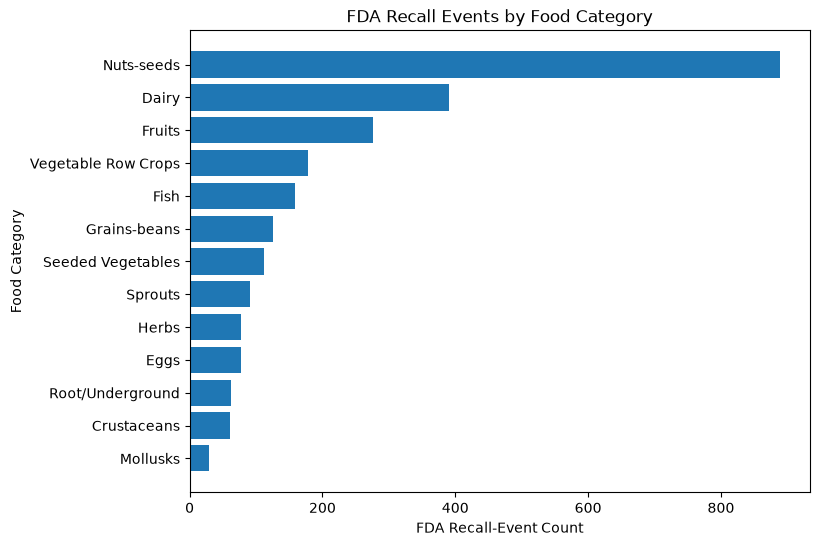

In [29]:
# Plot FDA recall-event counts for each food category.

food_plot_recall = food_summary.sort_values(
    "total_fda_recall_events",
    ascending=True
)

plt.figure(figsize=(8, 6))
plt.barh(
    food_plot_recall.index,
    food_plot_recall["total_fda_recall_events"]
)
plt.xlabel("FDA Recall-Event Count")
plt.ylabel("Food Category")
plt.title("FDA Recall Events by Food Category")
plt.show()

The food-category summaries differ, which supports focusing the research question on the degree of alignment instead of assuming that the two systems should match closely.

### 5.5 Changes Across Years

Because the final dataset is an annual panel, we also examine whether total CDC illness burden and FDA recall activity change over time.

We plot annual totals on a `log(1 + x)` scale so that both measures can be shown clearly despite their different magnitudes. This plot is descriptive and does not replace either planned regression.

Summarize CDC-recorded illnesses and FDA recall events by year and plot their annual patterns.

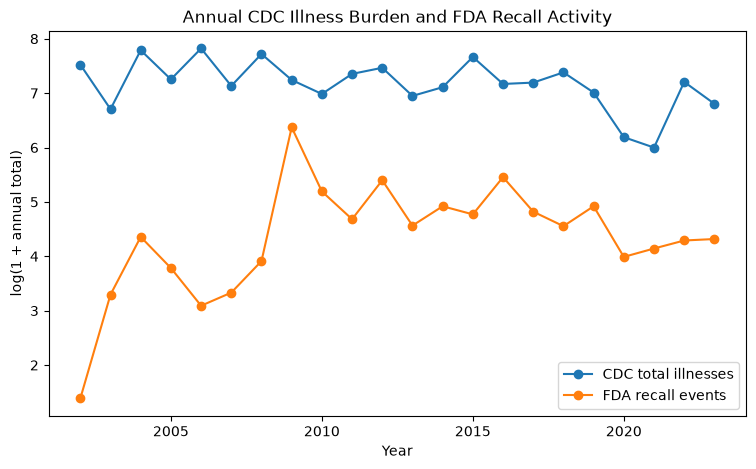

In [30]:
# Summarize and plot annual CDC illness burden and FDA recall activity.

annual_summary = (
    analysis_df
    .groupby("year")
    .agg(
        total_illnesses=("total_illnesses", "sum"),
        total_fda_recall_events=("fda_recall_events", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.plot(
    annual_summary["year"],
    np.log1p(annual_summary["total_illnesses"]),
    marker="o",
    label="CDC total illnesses"
)
plt.plot(
    annual_summary["year"],
    np.log1p(annual_summary["total_fda_recall_events"]),
    marker="o",
    label="FDA recall events"
)

plt.xlabel("Year")
plt.ylabel("log(1 + annual total)")
plt.title("Annual CDC Illness Burden and FDA Recall Activity")
plt.legend()
plt.show()

The annual totals vary across the study period instead of remaining constant. This supports including year as a control in the planned regression models.

### 5.6 EDA Summary

The EDA supports continuing with the research question in the final analysis.

The data do **not show a strong or consistent relationship** between CDC-recorded illness burden and FDA recall activity. The yearly panel also has many zero-event rows, and the plots show differences across pathogens, food categories, and years.

The count variables are strongly right-skewed, so we plan to use `log(1 + x)` in later models. This reduces the effect of very large values while keeping zeros.

These results are descriptive only. The planned statistical analyses have not been run.

## 6. Preregistration Statement 1

### Hypothesis

Food-category × pathogen × year rows with greater CDC-recorded illness burden will have greater FDA recall activity.

### Observations

Each observation will be one **food-category × pathogen × year** row in the final dataset.

### Outcome Variable

`log(1 + fda_recall_events)`

### Main Predictor

`log(1 + total_illnesses)`

### Controls

We will include **year**, **pathogen**, and **food category** as categorical controls. These controls help account for differences across years, pathogens, and food categories that may affect recall activity.

### Proposed Analysis

We will use linear regression to predict `log(1 + FDA recall events)` from `log(1 + CDC total illnesses)`, while controlling for year, pathogen, and food category.

Rows with a missing CDC illness total cannot be used in this model.

We predict that the illness-burden coefficient will be positive. We will report the coefficient estimate, uncertainty, and statistical significance whether or not the hypothesis is supported.



## 7. Preregistration Statement 2

### Hypothesis

The relationship between CDC-recorded illness burden and FDA recall activity differs between **produce** and **non-produce** food categories.

We use produce status as a prespecified broader grouping so that this analysis tests one interpretable difference in slopes instead of fitting a separate interaction for every food category.

We define **produce** as:

- Fruits
- Vegetable Row Crops
- Seeded Vegetables
- Sprouts
- Root/Underground
- Herbs

All other food categories in the final dataset are treated as non-produce.

### Observations

Each observation will be one **food-category × pathogen × year** row in the final dataset.

### Outcome Variable

`log(1 + fda_recall_events)`

### Predictor Variables

- `log(1 + total_illnesses)`
- produce status
- the interaction between `log(1 + total_illnesses)` and produce status
- year as a categorical control
- pathogen as a categorical control

### Proposed Analysis

We will use linear regression to predict `log(1 + FDA recall events)` from `log(1 + CDC total illnesses)`, produce status, and their interaction, while controlling for year and pathogen.

The interaction tests whether the relationship between `log(1 + total_illnesses)` and `log(1 + fda_recall_events)` has a different slope for produce and non-produce rows.

We will test whether the interaction coefficient differs from 0.

Rows with a missing CDC illness total cannot be used in this model.

We do not include food category as a separate categorical control because this preregistered analysis focuses on the broader produce versus non-produce grouping.

We will report the interaction estimate, uncertainty, and statistical significance regardless of the result.


## 8. Questions for Reviewers

1. Is the food-category × pathogen × year row the right level for comparing FDA recall activity with CDC illness burden?
2. Is it reasonable to keep every food-category × pathogen pair that appears in either dataset so we do not remove cases where only one source records activity?
3. Is setting annual event and burden counts to 0 when the relevant source has no recorded event for that row appropriate?
4. Because CDC does not provide a unique outbreak ID in this file, should we keep identical rows instead of deleting rows that might represent separate outbreaks?
5. Is removing food categories mainly regulated by USDA FSIS the right way to make CDC more comparable with the FDA data?
6. Are the FDA pathogen and food-category keyword rules clear and reasonable given that we report their coverage and manually inspect a sample?
7. Should the final regression do anything else to account for repeated years from the same food-category × pathogen pair?
8. Is the produce vs. non-produce interaction a useful and realistic second analysis?